# Phase 1 — Data Exploration and Verification
Run this notebook first before any other.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from pathlib import Path

print(f'pandas  : {pd.__version__}')
print(f'numpy   : {np.__version__}')
print(f'seaborn : {sns.__version__}')
print('All imports successful')

pandas  : 2.3.3
numpy   : 2.3.5
seaborn : 0.13.2
All imports successful


In [2]:
BASE    = Path('E:/project1/EW_MOGA_Project')
DATA    = BASE / 'data' / 'Brain Tumor.csv'
RESULTS = BASE / 'results'
FIGURES = BASE / 'figures'
RESULTS.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)

plt.rcParams.update({
    'font.family':'serif','font.size':11,
    'axes.titlesize':12,'axes.titleweight':'bold',
    'axes.labelsize':11,'axes.spines.top':False,
    'axes.spines.right':False,'savefig.dpi':300,
    'savefig.bbox':'tight','savefig.facecolor':'white',
    'figure.facecolor':'white',
})

FEATURE_COLS = ['Mean','Variance','Standard Deviation','Entropy',
    'Skewness','Kurtosis','Contrast','Energy',
    'ASM','Homogeneity','Dissimilarity','Correlation','Coarseness']

C0 = '#B6243C'
C1 = '#1F5FA8'
print('Configuration set')
print(f'Data : {DATA}')

Configuration set
Data : E:\project1\EW_MOGA_Project\data\Brain Tumor.csv


In [3]:
df = pd.read_csv(DATA)
print('='*50)
print(f'Shape          : {df.shape}')
print(f'Columns        : {df.columns.tolist()}')
print(f'Missing values : {df.isnull().sum().sum()}')
print(f'Duplicate rows : {df.duplicated().sum()}')
print('='*50)
df.head()

Shape          : (3762, 15)
Columns        : ['Image', 'Class', 'Mean', 'Variance', 'Standard Deviation', 'Entropy', 'Skewness', 'Kurtosis', 'Contrast', 'Energy', 'ASM', 'Homogeneity', 'Dissimilarity', 'Correlation', 'Coarseness']
Missing values : 0
Duplicate rows : 0


,Image,Class,Mean,Variance,Standard Deviation,Entropy,Skewness,Kurtosis,Contrast,Energy,ASM,Homogeneity,Dissimilarity,Correlation,Coarseness
0,Image1,0,6.535339,619.587845,24.891522,0.109059,4.276477,18.900575,98.613971,0.293314,0.086033,0.530941,4.473346,0.981939,7.458341e-155
1,Image2,0,8.749969,805.957634,28.389393,0.266538,3.718116,14.464618,63.858816,0.475051,0.225674,0.651352,3.220072,0.988834,7.458341e-155
2,Image3,1,7.341095,1143.808219,33.820234,0.001467,5.061750,26.479563,81.867206,0.031917,0.001019,0.268275,5.981800,0.978014,7.458341e-155
3,Image4,1,5.958145,959.711985,30.979219,0.001477,5.677977,33.428845,151.229741,0.032024,0.001026,0.243851,7.700919,0.964189,7.458341e-155
4,Image5,0,7.315231,729.540579,27.010009,0.146761,4.283221,19.079108,174.988756,0.343849,0.118232,0.501140,6.834689,0.972789,7.458341e-155


In [4]:
X = df[FEATURE_COLS].values.astype(float)
y = df['Class'].values.astype(int)
print(f'X shape : {X.shape}')
print(f'y shape : {y.shape}')
print(f'Class 0 (Non-tumor): {(y==0).sum()} ({100*(y==0).mean():.1f}%)')
print(f'Class 1 (Tumor)    : {(y==1).sum()} ({100*(y==1).mean():.1f}%)')

X shape : (3762, 13)
y shape : (3762,)
Class 0 (Non-tumor): 2079 (55.3%)
Class 1 (Tumor)    : 1683 (44.7%)


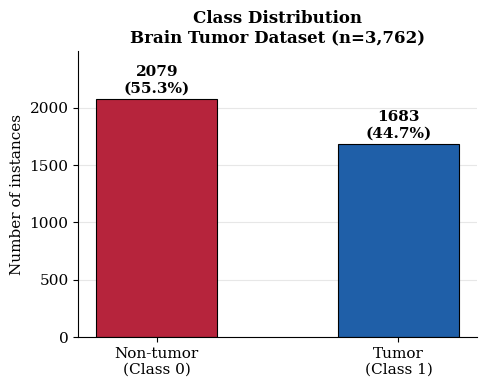

Saved class distribution plot


In [5]:
fig, ax = plt.subplots(figsize=(5,4))
counts = [int((y==0).sum()), int((y==1).sum())]
labels = ['Non-tumor\n(Class 0)','Tumor\n(Class 1)']
bars = ax.bar(labels, counts, color=[C0,C1], edgecolor='black', linewidth=0.8, width=0.5)
for bar, count in zip(bars, counts):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+30,
            f'{count}\n({100*count/len(y):.1f}%)',
            ha='center', va='bottom', fontsize=11, fontweight='bold')
ax.set_ylabel('Number of instances')
ax.set_title('Class Distribution\nBrain Tumor Dataset (n=3,762)')
ax.set_ylim(0, max(counts)*1.2)
ax.yaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(FIGURES/'class_distribution.png')
plt.savefig(FIGURES/'class_distribution.pdf')
plt.show()
print('Saved class distribution plot')

In [6]:
stats = pd.DataFrame({
    'Feature'  : FEATURE_COLS,
    'Mean'     : X.mean(axis=0).round(4),
    'Std'      : X.std(axis=0).round(4),
    'Min'      : X.min(axis=0).round(4),
    'Max'      : X.max(axis=0).round(4),
    'Mean_C0'  : X[y==0].mean(axis=0).round(4),
    'Mean_C1'  : X[y==1].mean(axis=0).round(4),
}).set_index('Feature')
print(stats.to_string())
stats.to_csv(RESULTS/'descriptive_statistics.csv')
print('Saved descriptive_statistics.csv')

                        Mean       Std     Min        Max   Mean_C0   Mean_C1
Feature                                                                      
Mean                  9.4889    5.7273  0.0787    33.2400    9.9822    8.8795
Variance            711.1011  467.4048  3.1456  2910.5819  581.2304  871.5295
Standard Deviation   25.1823    8.7724  1.7736    53.9498   22.9283   27.9665
Entropy               0.0736    0.0703  0.0009     0.3945    0.1228    0.0128
Skewness              4.1027    2.5606  1.8860    36.9313    3.1751    5.2486
Kurtosis             24.3891   56.4272  3.9424  1371.6401   12.2123   39.4310
Contrast            127.9615  109.4850  3.1947  3382.5742  107.0145  153.8371
Energy                0.2047    0.1293  0.0247     0.5897    0.3051    0.0807
ASM                   0.0586    0.0583  0.0006     0.3477    0.0984    0.0095
Homogeneity           0.4793    0.1279  0.1055     0.8109    0.5768    0.3588
Dissimilarity         4.6985    1.8499  0.6811    27.8278    3.7

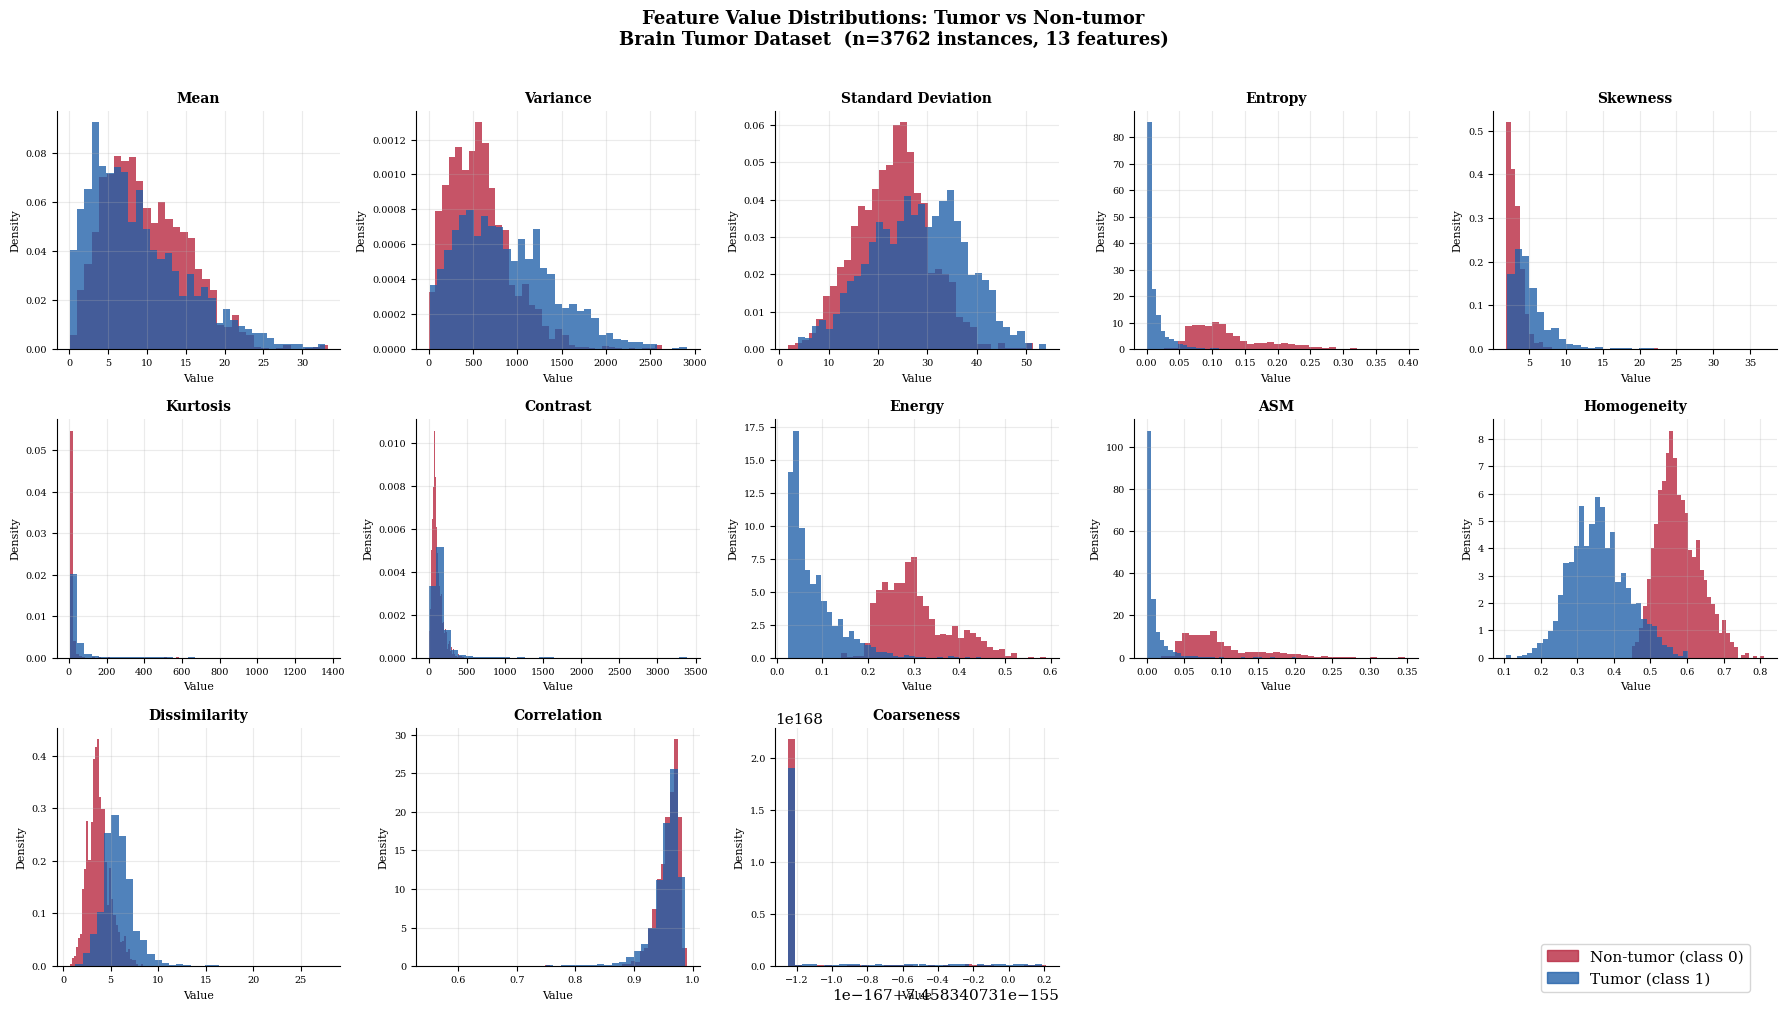

Saved feature distributions figure


In [7]:
fig, axes = plt.subplots(3,5,figsize=(18,10))
axes = axes.flatten()
for i, feat in enumerate(FEATURE_COLS):
    ax = axes[i]
    ax.hist(X[y==0,i], bins=35, alpha=0.78, color=C0, density=True, edgecolor='none')
    ax.hist(X[y==1,i], bins=35, alpha=0.78, color=C1, density=True, edgecolor='none')
    ax.set_title(feat, fontsize=10, fontweight='bold')
    ax.set_xlabel('Value', fontsize=8)
    ax.set_ylabel('Density', fontsize=8)
    ax.tick_params(labelsize=7)
    ax.grid(True, alpha=0.25)
for j in range(len(FEATURE_COLS), len(axes)):
    axes[j].set_visible(False)
handles = [mpatches.Patch(color=C0,alpha=0.78,label='Non-tumor (class 0)'),
           mpatches.Patch(color=C1,alpha=0.78,label='Tumor (class 1)')]
fig.legend(handles=handles, loc='lower right', fontsize=11,
           frameon=True, bbox_to_anchor=(0.98,0.02))
fig.suptitle('Feature Value Distributions: Tumor vs Non-tumor\n'
             f'Brain Tumor Dataset  (n={len(y)} instances, {len(FEATURE_COLS)} features)',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(FIGURES/'figA_dataset_distributions.png', bbox_inches='tight')
plt.savefig(FIGURES/'figA_dataset_distributions.pdf', bbox_inches='tight')
plt.show()
print('Saved feature distributions figure')

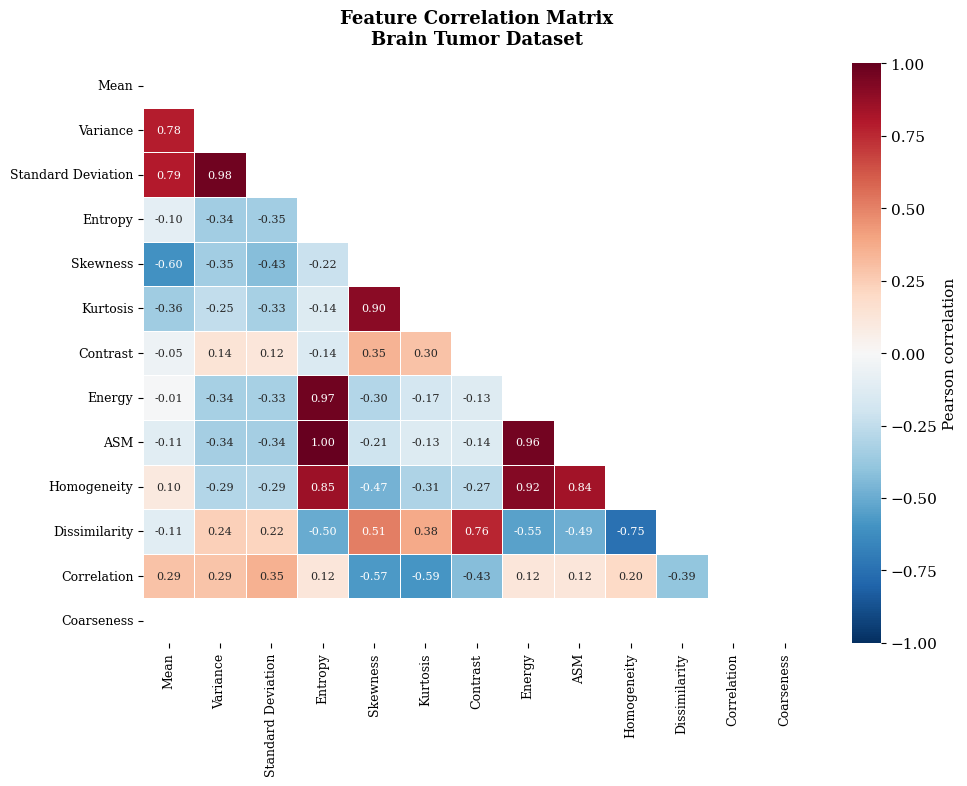

Saved correlation heatmap


In [8]:
fig, ax = plt.subplots(figsize=(10,8))
corr_matrix = pd.DataFrame(X, columns=FEATURE_COLS).corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, ax=ax, cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, annot=True, fmt='.2f',
            annot_kws={'size':8}, linewidths=0.5,
            cbar_kws={'label':'Pearson correlation'})
ax.set_title('Feature Correlation Matrix\nBrain Tumor Dataset', pad=14, fontsize=13, fontweight='bold')
ax.tick_params(labelsize=9)
plt.tight_layout()
plt.savefig(FIGURES/'feature_correlation.png')
plt.savefig(FIGURES/'feature_correlation.pdf')
plt.show()
print('Saved correlation heatmap')

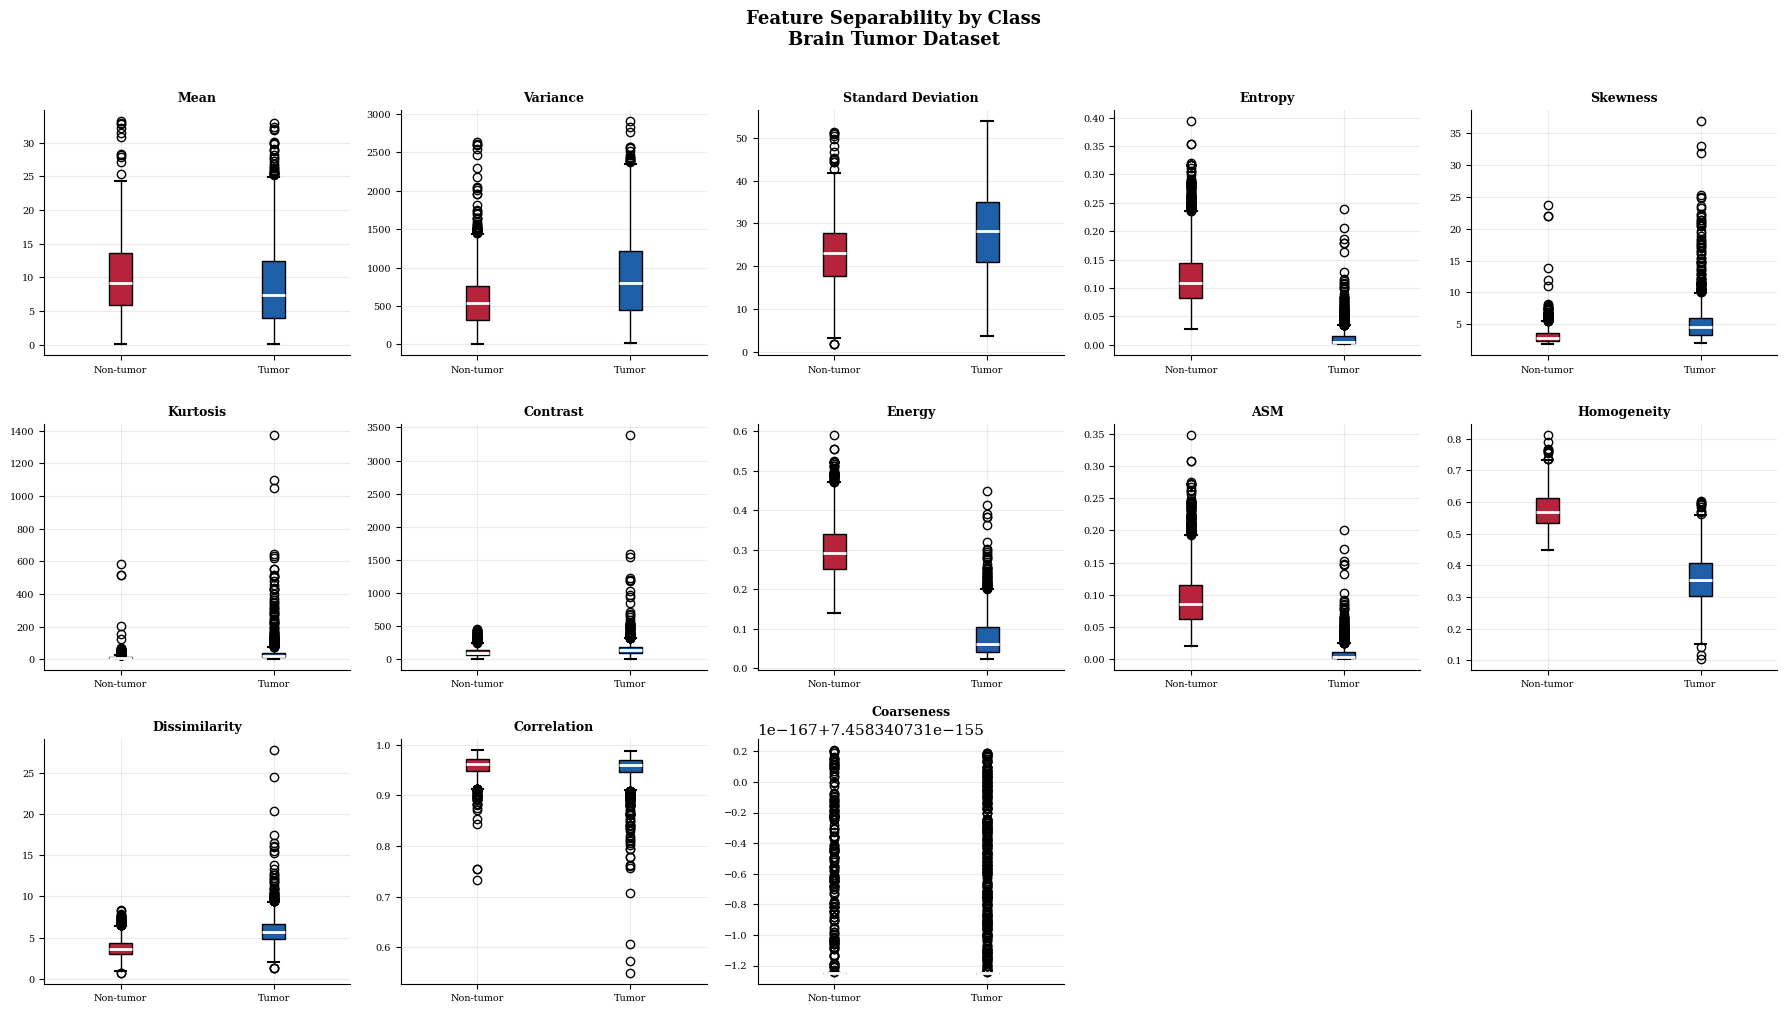

Saved feature separability plot


In [9]:
fig, axes = plt.subplots(3,5,figsize=(18,10))
axes = axes.flatten()
for i, feat in enumerate(FEATURE_COLS):
    ax = axes[i]
    data = [X[y==0,i], X[y==1,i]]
    bp = ax.boxplot(data, patch_artist=True,
                    medianprops=dict(color='white',linewidth=2),
                    boxprops=dict(linewidth=1),
                    whiskerprops=dict(linewidth=1),
                    capprops=dict(linewidth=1.5))
    bp['boxes'][0].set_facecolor(C0)
    bp['boxes'][1].set_facecolor(C1)
    ax.set_title(feat, fontsize=9, fontweight='bold')
    ax.set_xticklabels(['Non-tumor','Tumor'], fontsize=8)
    ax.tick_params(labelsize=7)
    ax.grid(True, alpha=0.25)
for j in range(len(FEATURE_COLS), len(axes)):
    axes[j].set_visible(False)
fig.suptitle('Feature Separability by Class\nBrain Tumor Dataset',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(FIGURES/'feature_separability.png', bbox_inches='tight')
plt.savefig(FIGURES/'feature_separability.pdf', bbox_inches='tight')
plt.show()
print('Saved feature separability plot')

In [10]:
print('='*55)
print('NOTEBOOK 1 COMPLETE')
print('='*55)
print(f'Total instances    : {len(y)}')
print(f'Total features     : {len(FEATURE_COLS)}')
print(f'Non-tumor (class 0): {(y==0).sum()}')
print(f'Tumor (class 1)    : {(y==1).sum()}')
print(f'Missing values     : {np.isnan(X).sum()}')
print(f'Duplicate rows     : {df.duplicated().sum()}')
print()
print('Ready to run Notebook 2')
print('='*55)

NOTEBOOK 1 COMPLETE
Total instances    : 3762
Total features     : 13
Non-tumor (class 0): 2079
Tumor (class 1)    : 1683
Missing values     : 0
Duplicate rows     : 0

Ready to run Notebook 2
